In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

C:\Users\PMLS\AppData\Roaming\Python\Python313\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
C:\Users\PMLS\AppData\Roaming\Python\Python313\site-packages\pandas\core\arrays\masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [2]:
data = {
    "study_hours": [
        1, 2, 3, 4, 5, 6, 7, 8, 2, 3,
        4, 5, 6, 7, 8, 1, 2, 3, 6, 7
    ],

    "attendance": [
        30, 40, 50, 55, 60, 70, 80, 90, 35, 45,
        60, 65, 75, 85, 95, 20, 30, 40, 80, 90
    ],

    "result": [
        0, 0, 0, 0, 1, 1, 1, 1, 0, 0,
        1, 1, 1, 1, 1, 0, 0, 0, 1, 1
    ]
}

df = pd.DataFrame(data)

print(df)

    study_hours  attendance  result
0             1          30       0
1             2          40       0
2             3          50       0
3             4          55       0
4             5          60       1
5             6          70       1
6             7          80       1
7             8          90       1
8             2          35       0
9             3          45       0
10            4          60       1
11            5          65       1
12            6          75       1
13            7          85       1
14            8          95       1
15            1          20       0
16            2          30       0
17            3          40       0
18            6          80       1
19            7          90       1


In [3]:
X = df[["study_hours", "attendance"]]

y = df["result"]

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16, 2)
Testing data: (4, 2)


In [5]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [6]:
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(shape=(2,)),

    layers.Dense(8, activation="relu"),

    layers.Dense(4, activation="relu"),

    layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 65 (260.00 B)

 Trainable params: 65 (260.00 B)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [8]:
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 65 (260.00 B)

 Trainable params: 65 (260.00 B)

 Non-trainable params: 0 (0.00 B)

In [9]:
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=4,
    validation_split=0.2,
    verbose=1
)


Epoch 1/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 142ms/step - accuracy: 0.6667 - loss: 0.7117 - val_accuracy: 0.2500 - val_loss: 0.7476
Epoch 2/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.6667 - loss: 0.7080 - val_accuracy: 0.2500 - val_loss: 0.7441
Epoch 3/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.6667 - loss: 0.7048 - val_accuracy: 0.2500 - val_loss: 0.7406
Epoch 4/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.6667 - loss: 0.7017 - val_accuracy: 0.2500 - val_loss: 0.7368
Epoch 5/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.6667 - loss: 0.6983 - val_accuracy: 0.2500 - val_loss: 0.7333
Epoch 6/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.6667 - loss: 0.6953 - val_accuracy: 0.2500 - val_loss: 0.7299
Epoch 7/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.6667 - loss: 0.6921 - val_accuracy: 0.2500 - val_loss: 0.7263
Epoch 8/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.6667 - loss: 0.6887 - val_accuracy: 0.2500 - val_loss: 0.7230

In [10]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 236ms/step - accuracy: 0.5000 - loss: 0.5932
Test Loss: 0.5931969881057739
Test Accuracy: 0.5


In [11]:
predictions = model.predict(X_test)

predicted_classes = (predictions >= 0.5).astype(int)

print("Actual results:", y_test.values)
print("Predicted results:", predicted_classes.flatten())

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step
Actual results: [0 1 1 0]
Predicted results: [1 1 1 1]


In [12]:
print("Prediction probabilities:")
print(predictions.flatten())

Prediction probabilities:
[0.5381803  0.6643833  0.63175845 0.5190841 ]


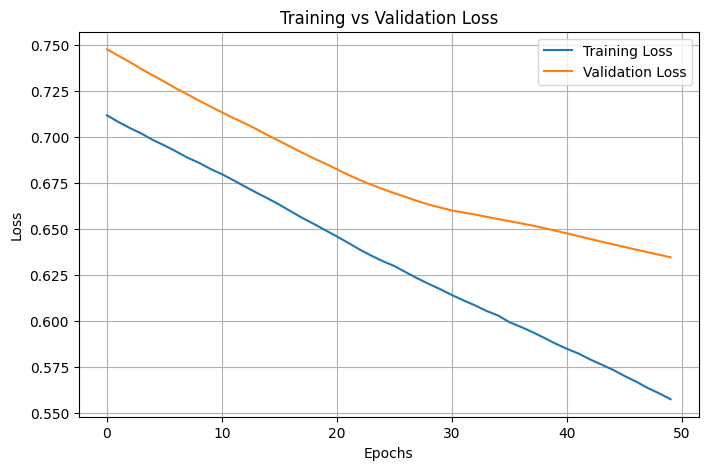

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.grid()
plt.show()

In [14]:
from tensorflow import keras
from tensorflow.keras import layers

def create_model():

    model = keras.Sequential([
        layers.Input(shape=(2,)),
        layers.Dense(8, activation="relu"),
        layers.Dense(4, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])

    return model

In [15]:
sgd_model = create_model()

sgd_model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

sgd_history = sgd_model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=4,
    validation_split=0.2,
    verbose=0
)

In [16]:
adam_model = create_model()

adam_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

adam_history = adam_model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=4,
    validation_split=0.2,
    verbose=0
)

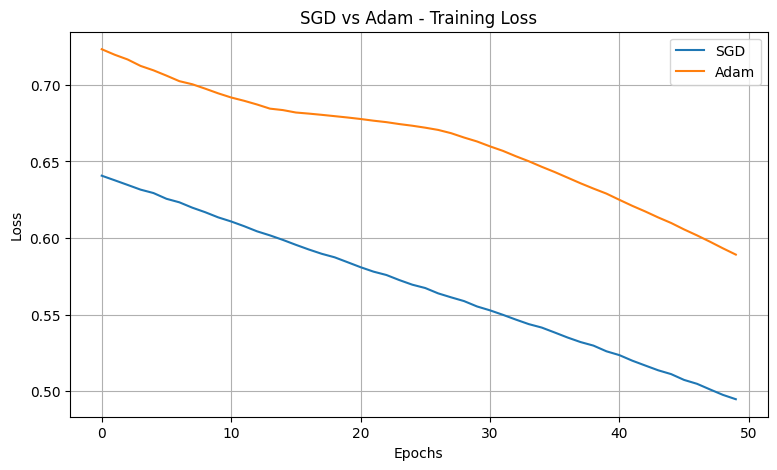

In [17]:
plt.figure(figsize=(9, 5))

plt.plot(sgd_history.history["loss"], label="SGD")
plt.plot(adam_history.history["loss"], label="Adam")

plt.title("SGD vs Adam - Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.grid()
plt.show()

In [18]:
print("SGD Final Training Loss:",
      sgd_history.history["loss"][-1])

print("Adam Final Training Loss:",
      adam_history.history["loss"][-1])

print("SGD Final Validation Loss:",
      sgd_history.history["val_loss"][-1])

print("Adam Final Validation Loss:",
      adam_history.history["val_loss"][-1])

SGD Final Training Loss: 0.4946678876876831
Adam Final Training Loss: 0.5891542434692383
SGD Final Validation Loss: 0.49776536226272583
Adam Final Validation Loss: 0.61612868309021
